**Лабораторная работа №4 для дикторской модели из лабораторной работы №6**

In [1]:
# IPython extension to reload modules before executing user code
%load_ext autoreload
%autoreload 2

# Import of modules
import os
import sys

sys.path.append(os.path.realpath('..'))

from math import sqrt, pi

import numpy as np
from matplotlib.pyplot import figure, subplot, hist, plot, show, grid, title, xlabel, ylabel, legend, axis, imshow, xticks, yticks
from scipy.stats import norm
import torch
from torch.utils.data import DataLoader
import itertools

from common import download_dataset, extract_dataset, download_protocol
from common import test_dataset_loader
from common import get_eer, get_dcf
from common import extract_features, compute_scores
from LoadModel import load_model
from ResNetSE34V2 import MainModel
from exercises_blank import tar_imp_hists, llr, map_test, neyman_pearson_test, bayes_test, minmax_test, error_rates, average_cost

In [2]:
# Load scores of the lab 6 model (computed by ../lab6/dump_scores.py)
EXP = 'base' # 'base' or 'freeze'

data       = np.load('../data/lab6_scores_%s.npz'%EXP)
all_scores = list(data['scores'])
all_labels = list(data['labels'])

print('Experiment: {0}, trials: {1}, target: {2}, impostor: {3}'.format(EXP, len(all_labels), sum(all_labels), len(all_labels) - sum(all_labels)))


Experiment: base, trials: 37611, target: 18802, impostor: 18809


**1. Таргет- и импостор-гистограммы оценок сравнения моделей**

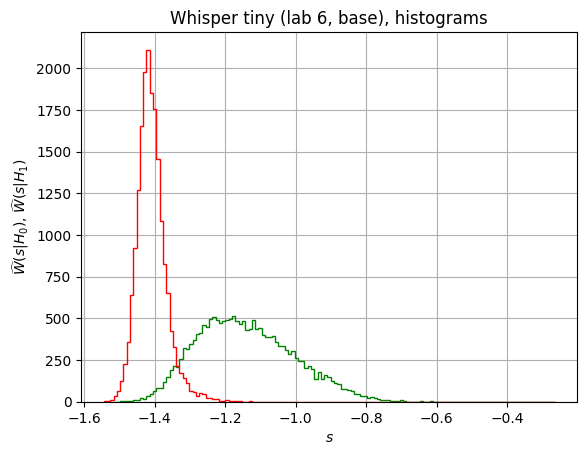

In [3]:
# Compute target and impostor histogram
tar_scores, imp_scores = tar_imp_hists(all_scores, all_labels)

# Plot histograms for target and impostor scores
min_scores = np.concatenate((tar_scores, imp_scores)).min()
max_scores = np.concatenate((tar_scores, imp_scores)).max()

hist(tar_scores, int(sqrt(len(tar_scores))), histtype='step', color='green', range=(min_scores, max_scores))
hist(imp_scores, int(sqrt(len(imp_scores))), histtype='step', color='red',   range=(min_scores, max_scores))
xlabel('$s$'); ylabel('$\widehat{W}(s|H_0)$, $\widehat{W}(s|H_1)$'); title('Whisper tiny (lab 6, %s), histograms'%EXP); grid(); show()

**2. Логарифм отношения правдоподобия и критерии принятия решения**

In [4]:
# Gaussian probability density function
gauss_pdf = lambda score, mu, sigma: 1/((abs(sigma) + 1e-10)*sqrt(2*pi))*np.exp(-(score - mu)**2/(2*(abs(sigma) + 1e-10)**2))

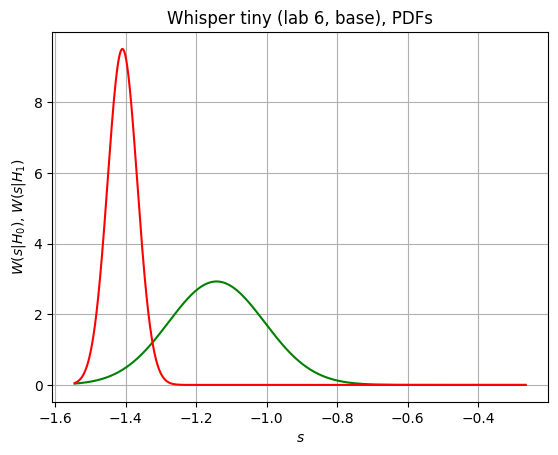

In [5]:
# Compute log-likelihood ratio
ground_truth_sort, all_scores_sort, tar_gauss_pdf, imp_gauss_pdf, LLR = llr(all_scores, all_labels, tar_scores, imp_scores, gauss_pdf)

# Plot PDFs for target and impostor scores
plot(all_scores_sort, tar_gauss_pdf, color='green')
plot(all_scores_sort, imp_gauss_pdf, color='red')
xlabel('$s$'); ylabel('$W(s|H_0)$, $W(s|H_1)$'); title('Whisper tiny (lab 6, %s), PDFs'%EXP); grid(); show()

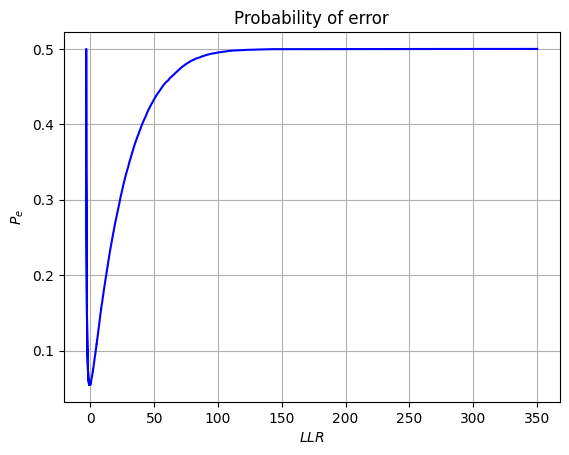

Threshold value:      -0.519
False negative rate:  0.063
False positive rate:  0.046
Probability of error: 0.054


In [6]:
# Maximum-likelihood test and maximum a posteriori (MAP) test. MAP is the same as Minimum Probability of Error Test
P_Htar = 1/2 # prob. of target hypothesis

llr_thr_val, fnr_thr_val, fpr_thr_val, P_err_min = map_test(ground_truth_sort, LLR, tar_scores, imp_scores, P_Htar)

print('Threshold value:      {0:.3f}'.format(llr_thr_val))
print('False negative rate:  {0:.3f}'.format(fnr_thr_val))
print('False positive rate:  {0:.3f}'.format(fpr_thr_val))
print('Probability of error: {0:.3f}'.format(P_err_min))

In [7]:
# Neyman-Pearson test
fnr    = 1/4 # given prob. of Type I error P(Dimp|Htar), false negative rate (FNR)

llr_thr_val, fpr_thr_val = neyman_pearson_test(ground_truth_sort, LLR, tar_scores, imp_scores, fnr)

print('Threshold value:      {0:.3f}'.format(llr_thr_val))
print('False negative rate:  {0:.3f}'.format(fnr))
print('False positive rate:  {0:.3f}'.format(fpr_thr_val))

Threshold value:      6.315
False negative rate:  0.250
False positive rate:  0.005


In [8]:
# Bayes' test
P_Htar = 1/2 # prob. of target hypothesis
C00    = 0   # cost of event (Dtar, Htar)
C10    = 1   # cost of event (Dimp, Htar)
C01    = 1   # cost of event (Dtar, Himp)
C11    = 0   # cost of event (Dimp, Himp)

llr_thr_val, fnr_thr_val, fpr_thr_val, AC_val = bayes_test(ground_truth_sort, LLR, tar_scores, imp_scores, P_Htar, C00, C10, C01, C11)

print('Threshold value:         {0:.3f}'.format(llr_thr_val))
print('False negative rate:     {0:.3f}'.format(fnr_thr_val))
print('False positive rate:     {0:.3f}'.format(fpr_thr_val))
print('Minimum of average cost: {0:.3f}'.format(AC_val))

Threshold value:         -0.519
False negative rate:     0.063
False positive rate:     0.046
Minimum of average cost: 0.054


In [9]:
# Minimax test
P_Htar_thr = np.linspace(0, 1, num=1000) # set of prob. of target hypothesis
C00        = 0                           # cost of event (Dtar, Htar)
C10        = 1                           # cost of event (Dimp, Htar)
C01        = 1                           # cost of event (Dtar, Himp)
C11        = 0                           # cost of event (Dimp, Himp)

llr_thr_val, fnr_thr_val, fpr_thr_val, AC_val, P_Htar_thr_val = minmax_test(ground_truth_sort, LLR, tar_scores, imp_scores, P_Htar_thr, C00, C10, C01, C11)

print('Threshold value:        {0:.3f}'.format(llr_thr_val))
print('False negative rate:    {0:.3f}'.format(fnr_thr_val))
print('False positive rate:    {0:.3f}'.format(fpr_thr_val))
print('Minmax of average cost: {0:.3f}'.format(AC_val))
print('Probability of Htar:    {0:.3f}'.format(P_Htar_thr_val))

Threshold value:        -1.094
False negative rate:    0.048
False positive rate:    0.063
Minmax of average cost: 0.055
Probability of Htar:    0.544


**3. Равновероятная ошибка, ROC- и DET-кривые, minDCF**

In [11]:
# Compute Equal Error Rate
EER, _ = get_eer(tar_scores, imp_scores)

print('Equal Error Rate (EER): {0:.3f}%'.format(EER))

Equal Error Rate (EER): 5.510%


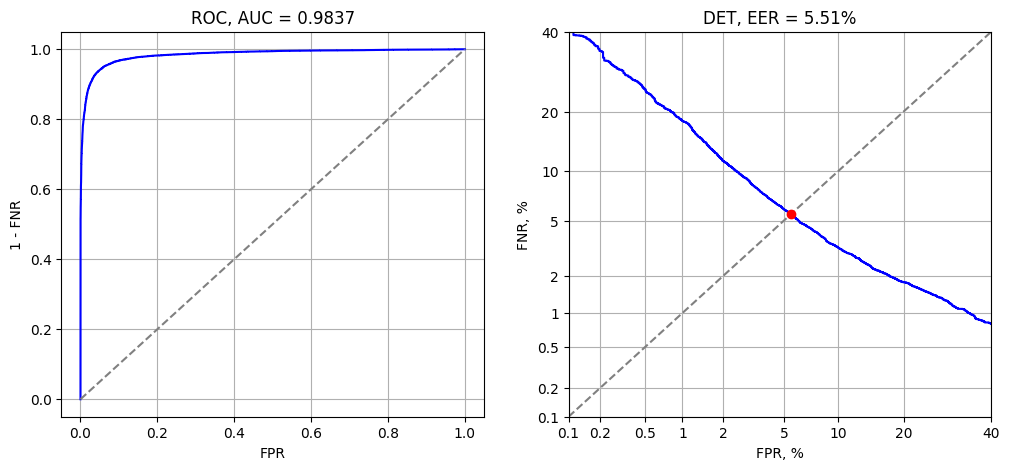

minDCF (P_target = 0.01): 0.4914
minDCF (P_target = 0.05): 0.3361


In [12]:
# ROC and DET curves over raw scores
thr_s   = np.sort(np.concatenate((tar_scores, imp_scores)))
fnr_s   = np.searchsorted(np.sort(tar_scores), thr_s, side='right')/len(tar_scores)
fpr_s   = 1 - np.searchsorted(np.sort(imp_scores), thr_s, side='right')/len(imp_scores)
AUC     = np.mean(tar_scores[:, None] > imp_scores[None, ::10]) # prob. that target score is higher than impostor score (subsampled impostors)

figure(figsize=(12, 5))

subplot(1, 2, 1)
plot(fpr_s, 1 - fnr_s, color='blue')
plot([0, 1], [0, 1], '--', color='gray')
xlabel('FPR'); ylabel('1 - FNR'); title('ROC, AUC = {0:.4f}'.format(AUC)); grid()

subplot(1, 2, 2)
ticks = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4])
eps   = 1e-6
plot(norm.ppf(np.clip(fpr_s, eps, 1 - eps)), norm.ppf(np.clip(fnr_s, eps, 1 - eps)), color='blue')
plot(norm.ppf(ticks[[0, -1]]), norm.ppf(ticks[[0, -1]]), '--', color='gray')
plot(norm.ppf(EER/100), norm.ppf(EER/100), 'o', color='red')
xticks(norm.ppf(ticks), ['{0:g}'.format(100*t) for t in ticks]); yticks(norm.ppf(ticks), ['{0:g}'.format(100*t) for t in ticks])
axis([norm.ppf(ticks[0]), norm.ppf(ticks[-1]), norm.ppf(ticks[0]), norm.ppf(ticks[-1])])
xlabel('FPR, %'); ylabel('FNR, %'); title('DET, EER = {0:.2f}%'.format(EER)); grid()
show()

for P_target in [0.01, 0.05]:
    minDCF, _, _, _ = get_dcf(tar_scores, imp_scores, P_target=P_target)
    print('minDCF (P_target = {0:.2f}): {1:.4f}'.format(P_target, minDCF))


In [13]:
# Scores of the pretrained ResNetSE34V2 (the same pipeline as in lab4_blank.ipynb), cached to a file
resnet_path = '../data/lab4_scores_resnet.npz'

if not os.path.exists(resnet_path):
    with open('../data/lists/models.txt', 'r') as f:
        model_lines = f.readlines()
    
    resnet = load_model(MainModel(), model_lines, save_path='../data/models').eval().cuda()
    
    with open('../data/voxceleb1_test/veri_test2.txt', 'r') as f:
        lines = f.readlines()
    
    setfiles     = sorted(set(itertools.chain(*[x.strip().split()[-2:] for x in lines])))
    test_dataset = test_dataset_loader(setfiles, test_path='../data/voxceleb1_test/wav/', eval_frames=200, num_eval=5)
    test_loader  = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=10, drop_last=False, sampler=None)
    
    resnet_scores, resnet_labels, _ = compute_scores(extract_features(resnet, test_loader), lines)
    np.savez(resnet_path, scores=np.array(resnet_scores), labels=np.array(resnet_labels))

systems = {'ResNetSE34V2 (pretrained)': resnet_path,
           'Whisper tiny, base (lab 6)':   '../data/lab6_scores_base.npz',
           'Whisper tiny, freeze (lab 6)': '../data/lab6_scores_freeze.npz'}
colors  = ['black', 'blue', 'orange']


Embedding size is 512, encoder ASP.
File baseline_v2_ap.model is downloaded.


D:\python_projects\ITMO\my_sr_labs_2026\lab4\ResNetSE34V2.py:105: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=False):


ResNetSE34V2 (pretrained)      EER  1.181%   minDCF(0.05) 0.0865
Whisper tiny, base (lab 6)     EER  5.510%   minDCF(0.05) 0.3361
Whisper tiny, freeze (lab 6)   EER  5.382%   minDCF(0.05) 0.4476


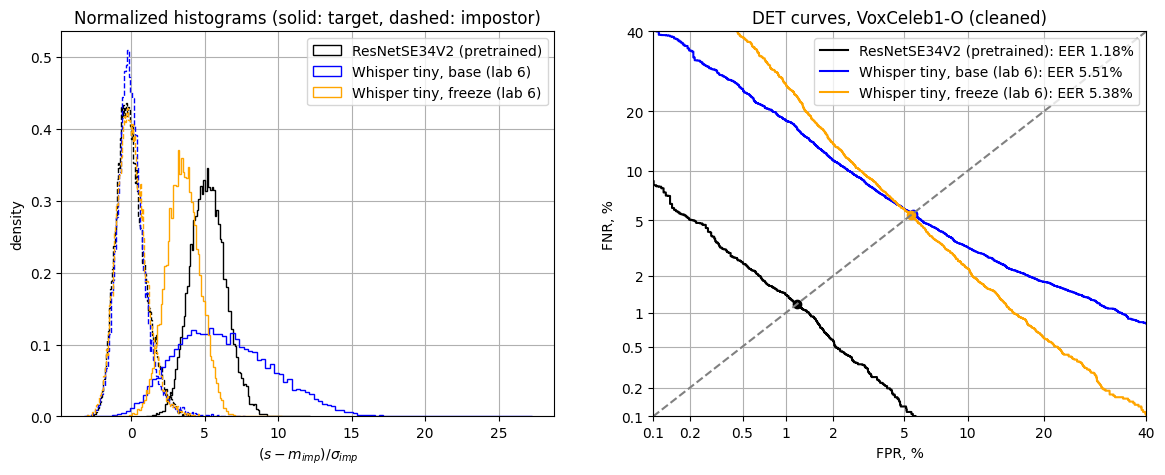

In [ ]:
figure(figsize=(14, 5))

for k, (name, path) in enumerate(systems.items()):
    d = np.load(path)
    tar, imp = tar_imp_hists(d['scores'], d['labels'])
    
    tar_n, imp_n = (tar - imp.mean())/imp.std(), (imp - imp.mean())/imp.std()
    
    subplot(1, 2, 1)
    hist(tar_n, 100, histtype='step', color=colors[k], density=True, label=name)
    hist(imp_n, 100, histtype='step', color=colors[k], density=True, linestyle='--')
    
    thr_s = np.sort(np.concatenate((tar, imp)))
    fnr_s = np.searchsorted(np.sort(tar), thr_s, side='right')/len(tar)
    fpr_s = 1 - np.searchsorted(np.sort(imp), thr_s, side='right')/len(imp)
    eer_k, _ = get_eer(tar, imp)
    minDCF_k, _, _, _ = get_dcf(tar, imp, P_target=0.05)
    
    subplot(1, 2, 2)
    plot(norm.ppf(np.clip(fpr_s, 1e-6, 1 - 1e-6)), norm.ppf(np.clip(fnr_s, 1e-6, 1 - 1e-6)), color=colors[k], label='{0}: EER {1:.2f}%'.format(name, eer_k))
    plot(norm.ppf(eer_k/100), norm.ppf(eer_k/100), 'o', color=colors[k])
    
    print('{0:30s} EER {1:6.3f}%   minDCF(0.05) {2:.4f}'.format(name, eer_k, minDCF_k))

subplot(1, 2, 1)
xlabel('$(s - m_{imp})/\sigma_{imp}$'); ylabel('density'); title('Normalized histograms (solid: target, dashed: impostor)'); grid(); legend()

subplot(1, 2, 2)
ticks = np.array([0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.4])
plot(norm.ppf(ticks[[0, -1]]), norm.ppf(ticks[[0, -1]]), '--', color='gray')
xticks(norm.ppf(ticks), ['{0:g}'.format(100*t) for t in ticks]); yticks(norm.ppf(ticks), ['{0:g}'.format(100*t) for t in ticks])
axis([norm.ppf(ticks[0]), norm.ppf(ticks[-1]), norm.ppf(ticks[0]), norm.ppf(ticks[-1])])
xlabel('FPR, %'); ylabel('FNR, %'); title('DET curves, VoxCeleb1-O (cleaned)'); grid(); legend(loc='upper right')
show()
